# Re-scoring Humanity's Last Exam: a Python walkthrough

**Preston Botter · Companion to [I Re-scored Humanity's Last Exam. Llama Fell 14 Places.](https://benchmarkanatomy.substack.com/p/i-re-scored-humanitys-last-exam-llama)**

How can the same answers produce different rankings? We compare percent correct
with unidimensional, bifactor, and higher-order IRT scores, using my transposed EM
algorithm.

**Run all cells in order.** They read the saved HLE results, calculate score comparisons,
and demonstrate one E-step and one M-step on synthetic data. They do not rerun
the expensive full analysis. Setup commands are in the accompanying README.
No API keys or new LLM responses are needed.

The hierarchical methods remain in development; their mathematics and implementation
may change. This notebook documents the version used in the manuscript.


## 1. Load the code

The estimator is imported unchanged. The memory wrapper uses the same equations,
accumulating derivatives in batches. The table below maps the main ideas to the code.

| Idea | Function |
| --- | --- |
| Response likelihood and item distribution | `_kernel` |
| Item posterior modes and quadrature | `item_modes`, `integrate` |
| E-step | `ExtendedTransposed.estep` |
| M-step | `ExtendedTransposed.mstep` |
| Iterate and check stopping rules | `ExtendedTransposed.fit` |
| Testlet to higher-order transformation | `higher_order` |
| Search starts and refine | `repeated_cv.coarse`, `repeated_cv.refine_impl` |


In [1]:
%matplotlib inline
import os, sys, ast, inspect, json
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

def locate_files():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "code/private_code/transposed_extended.py").exists():
            return base / "code", base / "results"
        candidate = base / "analysis/hle_scoring"
        if (candidate / "private_code/transposed_extended.py").exists():
            return candidate, base / "output/hle_article"
    raise FileNotFoundError("Open the notebook inside the complete companion folder.")

SOURCE, RESULTS = locate_files()
sys.path[:0] = [str(SOURCE), str(SOURCE / "private_code")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import pearsonr, spearmanr
from IPython.display import display, Code
from transposed_extended import ExtendedTransposed, Settings, higher_order, _kernel
from numerical_audit import MemoryBoundedTransposed

def show_function(filename, name):
    source = (SOURCE / filename).read_text()
    node = next(n for n in ast.parse(source).body
                if isinstance(n, ast.FunctionDef) and n.name == name)
    display(Code(ast.get_source_segment(source, node), language="python"))

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
print("Using the manuscript estimator and saved results.")


Using the manuscript estimator and saved results.


## 2. Read the response matrix

Rows are LLM configurations; columns are questions. `1` means correct, `0` incorrect,
and `NaN` missing. The source is [Sharma, Nadela, and Matteson (2026)](https://github.com/matrix-mayank/hle-psychometrics).
The HLE benchmark is described by [CAIS et al. (2026)](https://doi.org/10.1038/s41586-025-09962-4).

The manuscript keeps configurations with at least 95% coverage: **29 models and 513
text-only multiple-choice questions in eight subjects**. This is a subset of HLE.
All-incorrect questions remain included. Missing responses are not scored as wrong.

For model \(i\), with observed questions \(\mathcal O_i\):

$$
\operatorname{PercentCorrect}_i
=100\,\frac{\sum_{j\in\mathcal O_i}Y_{ij}}{|\mathcal O_i|}.
$$


In [2]:
responses = pd.read_csv(SOURCE / "primary_responses.csv", index_col=0)
items = pd.read_csv(SOURCE / "item_metadata.csv", index_col=0).loc[responses.columns]
domains = ["Biology/Medicine", "Math", "Humanities/Social Science",
           "Computer Science/AI", "Other", "Physics", "Chemistry", "Engineering"]
membership = np.array([domains.index(d) for d in items["category"]])
y = responses.to_numpy(float)
observed = np.isfinite(y)
percent_correct = 100 * np.nanmean(y, axis=1)

display(pd.Series({
    "Models": y.shape[0], "Questions": y.shape[1], "Subjects": len(domains),
    "Observed responses": observed.sum(), "Missing responses": (~observed).sum(),
    "All-incorrect questions": np.sum(np.nansum(y, axis=0) == 0),
}, name="Analysis sample").to_frame())
display(items["category"].value_counts().reindex(domains).rename("Questions").to_frame())


,Analysis sample
Models,29
Questions,513
Subjects,8
Observed responses,14760
Missing responses,117
All-incorrect questions,85


,Questions
category,
Biology/Medicine,147
Math,89
Humanities/Social Science,79
Computer Science/AI,66
Other,44
Physics,37
Chemistry,26
Engineering,25


## 3. Three IRT response models

IRT connects a response's probability to model capability and question properties
([Lord, 1980](https://doi.org/10.4324/9780203056615);
[Reckase, 2009](https://doi.org/10.1007/978-0-387-89976-3)).
Percent correct counts successes equally. IRT uses the response pattern and the
question characteristics specified by its model.

Let \(\sigma(z)=1/(1+e^{-z})\), and let \(d(j)\) be question \(j\)'s subject.

| Symbol | Meaning |
| --- | --- |
| \(g_i\) | LLM \(i\)'s general coordinate, playing the role of \(\theta_i\) |
| \(b_j\) | Question difficulty |
| \(a_j>0\) | General discrimination: how sharply probability changes with \(g_i\) |
| \(s_{id}\) | Additional subject-associated coordinate |
| \(c_j\) | Loading of question \(j\) on that additional coordinate |

$$
\begin{aligned}
\text{Unidimensional:}\quad
p_{ij}&=\sigma\{a_j(g_i-b_j)\},\\
\text{Bifactor:}\quad
p_{ij}&=\sigma\{a_j(g_i-b_j)+c_j s_{i,d(j)}\},\\
\text{Testlet:}\quad
p_{ij}&=\sigma\{a_j(g_i-b_j)+a_j\tau_{d(j)}s_{i,d(j)}\}.
\end{aligned}
$$

In the unidimensional model, \(g_i=b_j\) gives probability 0.5. With an additional
component, that interpretation requires its contribution to be zero.
The testlet model constrains the specific-to-general loading ratio within each subject.


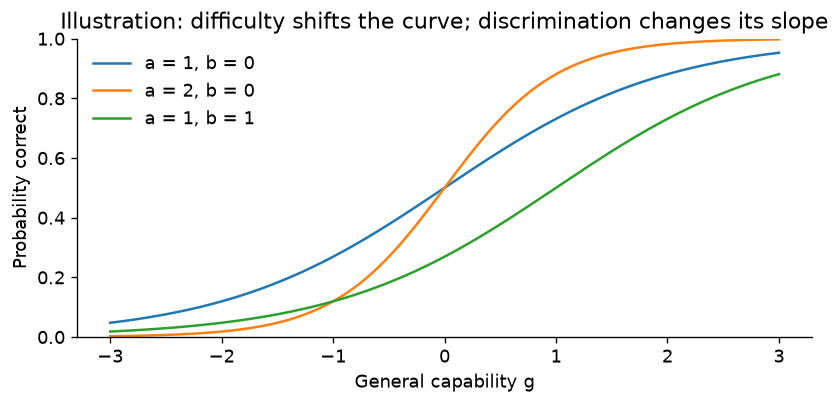

In [3]:
g_grid = np.linspace(-3, 3, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
for a, b, label in [(1, 0, "a = 1, b = 0"), (2, 0, "a = 2, b = 0"),
                    (1, 1, "a = 1, b = 1")]:
    ax.plot(g_grid, expit(a * (g_grid - b)), label=label)
ax.set(xlabel="General capability g", ylabel="Probability correct",
       title="Illustration: difficulty shifts the curve; discrimination changes its slope",
       ylim=(0, 1))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### What does the bifactor general score mean?

A conventional bifactor model has a general factor and mutually orthogonal secondary
factors ([Reise, 2012](https://doi.org/10.1080/00273171.2012.715555)).
For a reading test, a passage factor can represent extra similarity among answers
sharing the same passage. That helps distinguish broad reading proficiency from
passage-related influences ([DeMars, 2006](https://doi.org/10.1111/j.1745-3984.2006.00010.x)).

Here the clusters are subjects. Secondary coordinates describe residual components,
not full subject abilities. This implementation estimates **fixed, penalized coordinates**:
it uses the bifactor loading pattern but does not force their empirical correlations
across these 29 LLMs to be zero. The general score is not guaranteed to be a pure
or uniquely identified measure of capability.


## 4. Why transpose EM?

Here, **item effects are random and LLM scores are fixed unknown parameters**.
The algorithm integrates out item effects rather than integrating over an LLM ability
distribution. This is useful with many questions and relatively few models:
we estimate shared item-distribution parameters instead of freely optimizing
two or three parameters for every question
([Botter, 2026](https://doi.org/10.1080/15366367.2026.2720515)).
The specific regularized hierarchical extensions remain work in progress.

Write \(\eta_j=(b_j,\log a_j)\), adding \(c_j\) for the bifactor model, and let
\(\psi\) collect the fixed scores and distribution parameters. The likelihood is:

$$
\ell(\psi)=\sum_j\log\int
\left[\prod_{i:(i,j)\in\mathcal O}
p_{ij}^{Y_{ij}}(1-p_{ij})^{1-Y_{ij}}\right]
f(\eta_j\mid\psi)\,d\eta_j.
$$

Each question has **one shared item-effect vector**. Integrate after multiplying the
observed response probabilities for that question. Integrating separately for every
LLM would define a different model.

The manuscript uses MCAR as a working assumption for the original missing responses.
That assumption is not demonstrated by EM: likelihood methods can also accommodate
ignorable MAR under appropriate conditions
([Rubin, 1976](https://doi.org/10.1093/biomet/63.3.581)).


### Distributions and penalties used in this code

$$
b_j\sim N(\mu_{d(j)},2^2),\qquad
\log a_j\sim N(0,0.5^2),\qquad
c_j\sim N(\tau_{d(j)},0.75^2)\quad\text{(bifactor only)}.
$$

The working item dimensions are independent. All three models estimate subject-level
difficulty means \(\mu_d\), including the unidimensional model.

$$
\ell_{\rm pen}=\ell
-\frac{\gamma}{2}\sum_i g_i^2
-\frac{\gamma}{2}\sum_{i,d}s_{id}^2
-\frac{1}{2(2^2)}\sum_d\mu_d^2
-\frac12\sum_d\tau_d^2.
$$

The manuscript sets \(\gamma=1\). Terms involving \(s\) and \(\tau\) are absent in the
unidimensional model. Scores are bounded at \(\pm8\); \(\tau_d\) is bounded to
\([0,4]\) for bifactor and \([0,20]\) for testlet. These choices affect the decomposition.

The source below computes the **negative** conditional log likelihood plus the
item-distribution quadratic term. `eta[0]`, `eta[1]`, and `eta[2]` are \(b\), \(\log a\),
and \(c\). The observation mask excludes missing responses.


In [4]:
display(Code(inspect.getsource(_kernel), language="python"))


def _kernel(eta, y, mask, g, s, tau, mean, variance, family):
    a = jnp.exp(eta[1])
    c = eta[2] if family == "bifactor" else (a*tau if family == "testlet" else 0.)
    z = a*(g-eta[0]) + c*s
    return jnp.sum(mask*(jnp.logaddexp(0., z)-y*z)) + .5*jnp.sum((eta-mean)**2/variance)

## 5. Follow one E-step and one M-step

EM alternates between averaging over unobserved quantities and updating parameters
([Dempster, Laird, & Rubin, 1977](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x)).
Here the unobserved quantities are item effects.

**E-step:** find each item's posterior distribution under the current parameters:

$$
q_j^{(t)}(\eta_j)\propto
f(\eta_j\mid\psi^{(t)})
\prod_{i:(i,j)\in\mathcal O}p_{ij}^{Y_{ij}}(1-p_{ij})^{1-Y_{ij}}.
$$

The code approximates this distribution with adaptive Gauss-Hermite quadrature.
`nodes` are candidate item-effect vectors; `weights` are their posterior weights.
With \(q\) nodes per dimension, the grid has \(q^2\) points for unidimensional/testlet
and \(q^3\) for bifactor.

We use small **synthetic** data below so one update is quick to inspect.
The generating values are illustrative and are not fitted HLE results.


In [5]:
rng = np.random.default_rng(20261019)
toy_groups = np.repeat(np.arange(8), 4)  # Eight subjects, four questions each.
toy_g = rng.normal(size=12)
toy_s = rng.normal(size=(12, 8))
toy_b = rng.normal(1, 1.2, size=len(toy_groups))
toy_a = rng.lognormal(0, 0.4, size=len(toy_groups))
toy_p = expit(toy_a * (toy_g[:, None] - toy_b) + 0.5 * toy_s[:, toy_groups])
toy_y = rng.binomial(1, toy_p).astype(float)
toy_y[rng.random(toy_y.shape) < 0.03] = np.nan

example = MemoryBoundedTransposed(toy_y, toy_groups, "bifactor", Settings(points=3))
state0 = example.start(seed=1)
posterior0 = example.estep(state0)
display(pd.Series({
    "Synthetic models": toy_y.shape[0],
    "Synthetic questions": toy_y.shape[1],
    "Quadrature nodes per item": posterior0["weights"].shape[1],
    "First item's total posterior weight": posterior0["weights"][0].sum(),
    "First item's posterior mean difficulty":
        posterior0["weights"][0] @ posterior0["nodes"][0, :, 0],
}, name="One E-step").to_frame())


,One E-step
Synthetic models,12.000000
Synthetic questions,32.000000
Quadrature nodes per item,27.000000
First item's total posterior weight,1.000000
First item's posterior mean difficulty,-0.850919


**M-step:** improve the expected complete-data objective, with the E-step weights fixed:

$$
Q_{\rm pen}(\psi\mid\psi^{(t)})
=\sum_j E_{q_j^{(t)}}\!
\left[\log f(\eta_j\mid\psi)
+\sum_{i:(i,j)\in\mathcal O}\log\Pr(Y_{ij}\mid\eta_j,\psi)\right]
-P(\psi).
$$

`mstep` updates scores and distribution parameters. Newton steps and backtracking
seek an improvement rather than requiring a global maximizer at every step.
`fit` repeats these updates and uses safeguarded acceleration.
This is a regularized **generalized EM** implementation. Finite quadrature means the
recorded approximate marginal objective need not increase at every iteration.


In [6]:
state1, mstep_ok = example.mstep(state0, posterior0)
posterior1 = example.estep(state1)
display(pd.DataFrame({
    "Stage": ["Initialization", "After one M-step and a fresh E-step"],
    "Approximate penalized objective": [posterior0["objective"], posterior1["objective"]],
}))
print("Maximum change in a score coordinate:",
      round(float(np.max(np.abs(state1["scores"] - state0["scores"]))), 4))
print("One update illustrates the algorithm; it is not a converged fit.")


,Stage,Approximate penalized objective
0,Initialization,-246.428869
1,After one M-step and a fresh E-step,-205.036967


Maximum change in a score coordinate: 1.6571
One update illustrates the algorithm; it is not a converged fit.


## 6. Twenty starts, then numerical refinement

The manuscript used **20 random starts for every full-data fit**. Selection used the
highest approximate penalized objective within the same family and data mask.
Objectives are not used here to rank different model families.

The actual coarse-search function is shown below. It fits all requested seeds at
five-point quadrature. The selected candidate is then refined at higher orders and
checked for probability stability, score-equation residuals, and convergence.
Twenty starts find the best solution encountered, not a guaranteed global optimum.

This cell only displays the source; it does not launch another search.


In [7]:
show_function("repeated_cv.py", "coarse")


def coarse(task, family, seeds):
    _, train, group, _ = data_for(task)
    folder = RUN / task / family
    folder.mkdir(parents=True, exist_ok=True)
    # The coarse grid itself leaves a score residual near 0.001--0.003.
    # Search at a tolerance consistent with that grid, then impose the original
    # 0.001 criterion at high order. Earlier saved starts used the stricter
    # criterion and can be retained: the fitted objective is the same.
    est = ExtendedTransposed(train, group, family, Settings(points=5, max_iterations=240,
                                                          score_tolerance=5e-3))
    for seed in seeds:
        stem = folder / f'start_{seed:02d}_q5'
        if not stem.with_suffix('.json').exists():
            result = est.fit(seed, verbose=False)
            save(result, stem, compact=True)
            del result
        info = json.loads(stem.with_suffix('.json').read_text())
        print(json.dumps({'stage': 'restart', 'task': task, 'family': family, 'seed': seed,
                          'objective': info['objective'], 'converged': info['converged'],
                          'seconds': info['elapsed_seconds']}), flush=True)

In [8]:
restart_log = pd.read_csv(RESULTS / "restart_search.csv")
full_starts = restart_log[restart_log["analysis"] == "Full-data scores"]
selected = full_starts[full_starts["selected_for_refinement"]]
display(selected[["family", "seed", "search_quadrature_order",
                  "final_quadrature_order", "final_converged"]]
        .reset_index(drop=True))
print("Starts per full-data family:")
display(full_starts.groupby("family")["seed"].nunique().rename("Random starts").to_frame())


,family,seed,search_quadrature_order,final_quadrature_order,final_converged
0,unidimensional,11,5,15,True
1,bifactor,8,5,11,True
2,testlet,7,5,15,True


Starts per full-data family:


,Random starts
family,
bifactor,20
testlet,20
unidimensional,20


## 7. Interpret the testlet fit as a higher-order model

The proportional-loading restriction permits an exact change of coordinates
([Rijmen, 2010](https://doi.org/10.1111/j.1745-3984.2010.00118.x)):

$$
\lambda_d=(1+\tau_d^2)^{-1/2},\quad
h_{id}=\lambda_d(g_i+\tau_d s_{id}),\quad
a_j^*=a_j/\lambda_{d(j)},\quad b_j^*=b_j\lambda_{d(j)}.
$$

Then:

$$
a_j^*(h_{i,d(j)}-b_j^*)
=a_j(g_i-b_j)+a_j\tau_{d(j)}s_{i,d(j)}.
$$

The predictions are unchanged. \(g_i\) is general; \(h_{id}\) is the full subject
coordinate. This transformation carries the original item distribution and penalty
with it. It is not a separately fitted fourth model.


In [9]:
display(Code(inspect.getsource(higher_order), language="python"))
illustration = {"scores": np.array([[0.8, 0.2, -0.3]]), "tau": np.array([0.5, 1.0])}
loadings, subject_coordinates = higher_order(illustration)
display(pd.DataFrame({"Subject": ["A", "B"], "Loading": loadings,
                      "Higher-order coordinate": subject_coordinates[0]}))


def higher_order(state):
    tau=state['tau']; lam=1/np.sqrt(1+tau*tau)
    scores=state['scores']; h=(scores[:,0,None]+tau*scores[:,1:])*lam
    return lam,h

,Subject,Loading,Higher-order coordinate
0,A,0.894427,0.804984
1,B,0.707107,0.353553


## 8. Compare the full-data scores

**The reported scores use every observed HLE response in this analysis.**
They do not come from a train/test partition.
We standardize each general-score column for display; the scales are not percentages.


In [10]:
scores = pd.read_csv(RESULTS / "model_scores.csv").set_index("model_id")
scores = scores.loc[responses.index]
names = ["Llama 3.1 8B Instruct", "Claude Haiku 4.5", "Qwen2.5 7B Instruct"]
example_rows = scores[scores["display_name"].isin(names)]
display(example_rows[["display_name", "percent_correct", "unidimensional_rank",
                      "percent_rank", "bifactor_rank", "testlet_rank"]]
        .rename(columns={"testlet_rank": "higher_order_rank"})
        .reset_index(drop=True).round(3))


,display_name,percent_correct,unidimensional_rank,percent_rank,bifactor_rank,higher_order_rank
0,Claude Haiku 4.5,7.602,24.0,26.0,14.0,24.0
1,Qwen2.5 7B Instruct,11.891,15.0,11.0,24.0,15.0
2,Llama 3.1 8B Instruct,11.133,17.0,15.0,29.0,19.0


,Score,Pearson r,Spearman rho,100 × r² (scores),100 × rho² (ranks)
0,Unidimensional,0.97059,0.96797,94.20451,93.69706
1,Bifactor general,0.89900,0.76891,80.82071,59.12205
2,Higher-order general,0.96273,0.98054,92.68564,96.14530


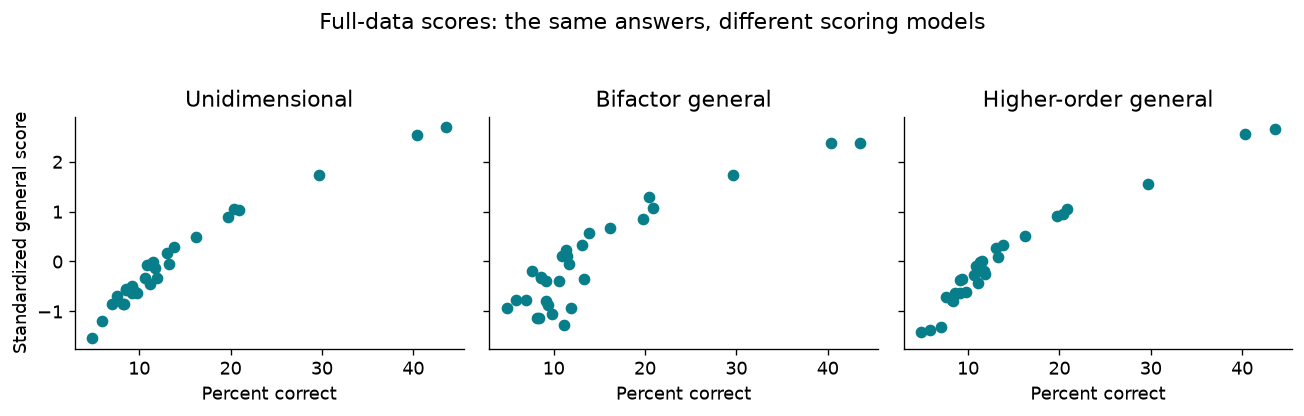

In [11]:
families = ["unidimensional", "bifactor", "testlet"]
labels = ["Unidimensional", "Bifactor general", "Higher-order general"]
comparison = []
for family, label in zip(families, labels):
    r = pearsonr(scores["percent_correct"], scores[family + "_score"]).statistic
    rho = spearmanr(scores["percent_correct"], scores[family + "_score"]).statistic
    comparison.append({"Score": label, "Pearson r": r, "Spearman rho": rho,
                       "100 × r² (scores)": 100*r*r, "100 × rho² (ranks)": 100*rho*rho})
display(pd.DataFrame(comparison).round(5))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, family, label in zip(axes, families, labels):
    ax.scatter(scores["percent_correct"], scores[family + "_z"], color="#087e8b")
    ax.set(title=label, xlabel="Percent correct")
axes[0].set_ylabel("Standardized general score")
fig.suptitle("Full-data scores: the same answers, different scoring models", y=1.04)
fig.tight_layout()
plt.show()


The bifactor **rank** correlation with percent correct is 0.76891:
59.12% shared variance in ranks. Its **Pearson score** correlation is 0.89900:
80.82% shared variance in scores. These are different summaries.
Here “shared variance” means the squared correlation, or the \(R^2\) from a
simple linear regression with an intercept; it is not a reliability estimate.
Neither correlation establishes which score interpretation is valid.


## 9. Predictive evaluation is a separate question<sup><a href="#cv-note">1</a></sup>

The manuscript's repeated cross-validation<sup><a href="#cv-note">1</a></sup> hides
observed responses in five folds, repeated three times. The same folds are used for
all three IRT models. Each fit has its own 20-start search and uses only its fitting
responses, including in item posteriors and initialization.

The target is **a missing response from a known model on a known item bank**.
This does not test new models or entirely new questions. Percent correct remains a
descriptive baseline and receives no predictive loss.

For held-out responses \(\mathcal V\):

$$
\operatorname{Brier}=\frac1{|\mathcal V|}\sum_{(i,j)\in\mathcal V}(p_{ij}-Y_{ij})^2,
$$
$$
\operatorname{LogLoss}=-\frac1{|\mathcal V|}\sum_{(i,j)\in\mathcal V}
\{Y_{ij}\log p_{ij}+(1-Y_{ij})\log(1-p_{ij})\}.
$$

Both are better when smaller. The code uses natural logarithms and clips probabilities
to avoid numerical logarithms of zero
([Brier, 1950](https://doi.org/10.1175/1520-0493%281950%29078%3C0001%3AVOFEIT%3E2.0.CO%3B2);
[Good, 1952](https://doi.org/10.1111/j.2517-6161.1952.tb00104.x)).
Proper scoring rules reward accurate probabilities in expectation
([Gneiting & Raftery, 2007](https://doi.org/10.1198/016214506000001437)).


In [12]:
# These are the actual masking and loss functions used by the analysis.
show_function("repeated_cv.py", "data_for")
show_function("repeated_cv.py", "losses")


def data_for(task):
    frame, group, folds = make_splits()
    y = frame.to_numpy(float)
    if task == 'full':
        valid = np.zeros_like(y, dtype=bool)
    else:
        repeat, fold = map(int, task.split('_'))
        valid = folds[repeat] == fold
    training = y.copy()
    training[valid] = np.nan
    assert not np.isfinite(training[valid]).any()
    return y, training, group, valid

def losses(y, prediction):
    p = np.clip(prediction, 1e-12, 1-1e-12)
    return {'n': int(len(y)), 'brier': float(np.mean((prediction-y)**2)),
            'log_loss': float(np.mean(-y*np.log(p)-(1-y)*np.log1p(-p)))}

In [13]:
predictive = pd.read_csv(RESULTS / "cv_summary.csv")
display(predictive[["label", "brier", "log_loss"]]
        .rename(columns={"label": "Model"}).round(6))
print("Lowest mean Brier:", predictive.loc[predictive["brier"].idxmin(), "label"])
print("Lowest mean log loss:", predictive.loc[predictive["log_loss"].idxmin(), "label"])


,Model,brier,log_loss
0,Unidimensional,0.099974,0.334927
1,Bifactor,0.099439,0.333872
2,Higher-order,0.101952,0.341750


Lowest mean Brier: Bifactor
Lowest mean log loss: Bifactor


Bifactor has the lowest mean loss on both measures, with small improvements over
unidimensional IRT. These losses assess the **whole response model**, including its
secondary components. They do not by themselves validate the general-score ranking.

<a id="cv-note"></a>**1. Evaluation caveat.** It has yet to be established to what extent
cross-validation should be one of the ways, or the only way, psychometric models are
evaluated and compared for LLM benchmarks. I have work in progress addressing this
question. Here it provides evidence about the stated prediction task.


## 10. Adapt the code

Supply a models-by-questions matrix with `0`, `1`, and `NaN`, plus one contiguous
zero-based subject index per question. The interface is:

```python
estimator = MemoryBoundedTransposed(y, membership, "bifactor", Settings(points=5))
result = estimator.fit(seed=1)
general = result["state"]["scores"][:, 0]
```

This single-start example shows the interface. A substantive analysis needs the
restart search, convergence and integration checks, and sensitivity assessment
described above. Question quality, missingness, dependence among models, and score
interpretation still need attention.

The `repeated_cv.py` source includes the original orchestration. Its historical
percentage-baseline helper was excluded from the final manuscript comparison and
is not called by this notebook or the companion validation.

The notebook, code, and supporting results are available in the [HLE IRT scoring repository](https://github.com/pbotter42/hle-irt-scoring).
Contact [pdbotter@gmail.com](mailto:pdbotter@gmail.com) to discuss the methods.


## References

- Botter, P. (2026). [Large language model benchmarks as measurement systems: Psychometric contributions and eight open problems](https://doi.org/10.1080/15366367.2026.2720515). *Measurement: Interdisciplinary Research and Perspectives*. Advance online publication.
- Brier, G. W. (1950). [Verification of forecasts expressed in terms of probability](https://doi.org/10.1175/1520-0493%281950%29078%3C0001%3AVOFEIT%3E2.0.CO%3B2). *Monthly Weather Review, 78*(1), 1–3.
- Center for AI Safety, Scale AI, & HLE Contributors Consortium. (2026). [A benchmark of expert-level academic questions to assess AI capabilities](https://doi.org/10.1038/s41586-025-09962-4). *Nature, 649*, 1139–1146.
- DeMars, C. E. (2006). [Application of the bi-factor multidimensional item response theory model to testlet-based tests](https://doi.org/10.1111/j.1745-3984.2006.00010.x). *Journal of Educational Measurement, 43*(2), 145–168.
- Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). [Maximum likelihood from incomplete data via the EM algorithm](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x). *Journal of the Royal Statistical Society: Series B, 39*(1), 1–22.
- Gneiting, T., & Raftery, A. E. (2007). [Strictly proper scoring rules, prediction, and estimation](https://doi.org/10.1198/016214506000001437). *Journal of the American Statistical Association, 102*(477), 359–378.
- Good, I. J. (1952). [Rational decisions](https://doi.org/10.1111/j.2517-6161.1952.tb00104.x). *Journal of the Royal Statistical Society: Series B, 14*(1), 107–114.
- Lord, F. M. (1980). [*Applications of item response theory to practical testing problems*](https://doi.org/10.4324/9780203056615). Lawrence Erlbaum Associates.
- Reckase, M. D. (2009). [*Multidimensional item response theory*](https://doi.org/10.1007/978-0-387-89976-3). Springer.
- Reise, S. P. (2012). [The rediscovery of bifactor measurement models](https://doi.org/10.1080/00273171.2012.715555). *Multivariate Behavioral Research, 47*(5), 667–696.
- Rijmen, F. (2010). [Formal relations and an empirical comparison among the bi-factor, the testlet, and a second-order multidimensional IRT model](https://doi.org/10.1111/j.1745-3984.2010.00118.x). *Journal of Educational Measurement, 47*(3), 361–372.
- Rubin, D. B. (1976). [Inference and missing data](https://doi.org/10.1093/biomet/63.3.581). *Biometrika, 63*(3), 581–592.
- Sharma, M., Nadela, S., & Matteson, T. (2026). [*HLE Psychometrics*](https://github.com/matrix-mayank/hle-psychometrics) [Data set and code]. GitHub.
